# Tiền xử lý và chia tập — so sánh trước – sau (Tuần 4)

**Mục đích:** kiểm tra và minh họa kết quả của `scripts/prepare_dataset.py`: tập dữ liệu sau khi làm sạch, cắt dải đệm phản
chiếu và chia train/val/test; thiết kế tăng cường dữ liệu và trọng số lớp cho các cấu hình M0, M1, M2.

**Quyết định đã chốt:**
- Cắt bỏ dải đệm phản chiếu ở cả 3 tập; bỏ các hộp có tâm nằm trong dải đệm, cắt các hộp còn lại theo biên vùng ảnh thật.
- Xóa các nhãn trùng đã được xác nhận khi kiểm định; giữ nguyên nhãn thiếu (nhiễu nhãn khoảng 1%) và hộp nhỏ hơn 4 pixel.
- Chia 70/15/15, phân tầng theo số hộp mỗi lớp, mỗi nhóm ảnh gần trùng nằm trọn trong một tập.
- Không đổi kích thước ảnh trên đĩa: Ultralytics tự đưa ảnh về `imgsz=640` khi huấn luyện, giữ nguyên tỉ lệ khung.
- M2 xử lý mất cân bằng lớp bằng tham số `cls_pw` của Ultralytics.

**Đầu vào:** `data/SHEL5K_processed/` (sinh bởi script), `reports/preprocessing/{split.csv, summary.json}`,
`reports/eda/image_stats.csv`. **Đầu ra:** biểu đồ trong `reports/preprocessing/`.

In [1]:
import json
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data/SHEL5K_processed"
REP = ROOT / "reports/preprocessing"
CLASSES = ["helmet", "head", "head_with_helmet", "person_with_helmet", "person_no_helmet", "face"]
SPLITS = ["train", "val", "test"]
PRIORITY = "person_no_helmet"

BLUE, ORANGE, AQUA, GRAY, INK, INK2, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#b9b8b2", "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "font.family": "Arial", "font.size": 10, "axes.edgecolor": INK2, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})

def save(fig, name):
    fig.savefig(REP / name)
    plt.show()

split = pd.read_csv(REP / "split.csv")
summary = json.loads((REP / "summary.json").read_text())
stats = pd.read_csv(ROOT / "reports/eda/image_stats.csv")
print(f"{len(split)} ảnh; các cột: {list(split.columns)[:12]} ...")

5000 ảnh; các cột: ['filename', 'unit', 'pad_axis', 'pad_width', 'width', 'height', 'crop_width', 'crop_height', 'boxes_before', 'duplicates_removed', 'boxes_in_pad', 'boxes_clipped'] ...


## 1. Tổng quan trước – sau

In [2]:
overview = pd.DataFrame([
    ("Số ảnh", summary["images"], summary["images"]),
    ("Số ảnh có dải đệm (được cắt)", summary["images_cropped"], 0),
    ("Số hộp", summary["boxes_before"], summary["boxes_after"]),
    ("Hộp nằm trong dải đệm (bỏ)", summary["boxes_in_pad_removed"], 0),
    ("Nhãn trùng đã xác nhận (xóa)", summary["duplicates_removed"], 0),
    ("Hộp bị cắt bớt theo biên vùng ảnh thật", "—", summary["boxes_clipped"]),
    ("Ảnh không còn nhãn", 0, summary["images_without_labels_after"]),
], columns=["Chỉ số", "Trước", "Sau"]).set_index("Chỉ số")
print(overview)
over = []  # lượng vượt biên (px) của các hộp có tâm trong vùng ảnh thật nhưng vắt sang dải đệm
for r in split[split.pad_axis.notna()].itertuples():
    lo, hi = r.pad_width, (r.height if r.pad_axis == "tb" else r.width) - r.pad_width
    for line in (ROOT / "data/SHEL5K_yolo/labels" / f"{r.filename}.txt").read_text().splitlines():
        c, x, y, w, h = map(float, line.split())
        a, b = ((y - h / 2) * r.height, (y + h / 2) * r.height) if r.pad_axis == "tb" else ((x - w / 2) * r.width, (x + w / 2) * r.width)
        if lo <= (a + b) / 2 < hi and max(lo - a, b - hi) > 0.5:
            over.append(max(lo - a, 0) + max(b - hi, 0))
over = pd.Series(over)
print(f"Hộp vắt qua biên vùng ảnh thật: {len(over)}; lượng bị cắt ≤ 5 px: {(over <= 5).mean() * 100:.0f}%, "
      f"> 10 px: {(over > 10).sum()} hộp (lớn nhất {over.max():.0f} px)")
print(f"\nSố hộp giảm {(1 - summary['boxes_after'] / summary['boxes_before']) * 100:.1f}%; "
      f"trung bình {summary['boxes_after'] / summary['images']:.1f} hộp/ảnh (trước: {summary['boxes_before'] / summary['images']:.1f})")

                                        Trước    Sau
Chỉ số                                              
Số ảnh                                   5000   5000
Số ảnh có dải đệm (được cắt)             4965      0
Số hộp                                  75578  66434
Hộp nằm trong dải đệm (bỏ)               9136      0
Nhãn trùng đã xác nhận (xóa)                8      0
Hộp bị cắt bớt theo biên vùng ảnh thật      —   2804
Ảnh không còn nhãn                          0      0


Hộp vắt qua biên vùng ảnh thật: 2804; lượng bị cắt ≤ 5 px: 72%, > 10 px: 323 hộp (lớn nhất 81 px)

Số hộp giảm 12.1%; trung bình 13.3 hộp/ảnh (trước: 15.1)


**Diễn giải.** Mọi ảnh đều được giữ lại; 4.965 ảnh được cắt dải đệm. Số hộp giảm 12,1% (75.578 → 66.434), gần như toàn
bộ do bỏ 9.136 bản sao phản chiếu; 8 nhãn trùng đã xác nhận bị xóa. 2.804 hộp vắt qua biên vùng ảnh thật được cắt bớt:
72% trong số đó chỉ lệch dưới 5 pixel (sai số ±1–2 pixel khi xác định biên dải đệm), còn 323 hộp lệch hơn 10 pixel là
hộp người được vẽ kéo dài sang phần chân phản chiếu — người gán nhãn SHEL5K vẽ trên ảnh đã có dải đệm — nay chỉ còn phần
người thật. Không ảnh nào mất hết nhãn.

## 2. Phân bố lớp trước – sau

                    before  after  thay đổi %  tỉ lệ trước %  tỉ lệ sau %
helmet               19252  15566       -19.1           25.5         23.4
head                  6120   5411       -11.6            8.1          8.1
head_with_helmet     16048  13887       -13.5           21.2         20.9
person_with_helmet   14775  13857        -6.2           19.5         20.9
person_no_helmet      5248   4980        -5.1            6.9          7.5
face                 14135  12733        -9.9           18.7         19.2
Tỉ lệ mất cân bằng trước: 3.67
Tỉ lệ mất cân bằng sau: 3.13


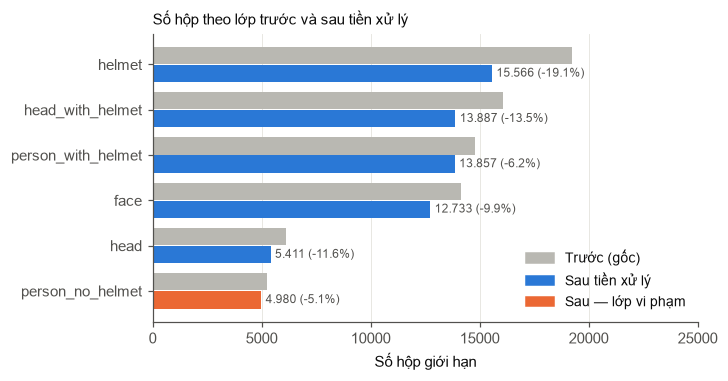

In [3]:
pc = pd.DataFrame(summary["per_class"]).T.reindex(CLASSES)
pc["thay đổi %"] = ((pc.after / pc.before - 1) * 100).round(1)
pc["tỉ lệ trước %"] = (pc.before / pc.before.sum() * 100).round(1)
pc["tỉ lệ sau %"] = (pc.after / pc.after.sum() * 100).round(1)
print(pc)
for col, lab in [("before", "trước"), ("after", "sau")]:
    print(f"Tỉ lệ mất cân bằng {lab}: {pc[col].max() / pc.loc[PRIORITY, col]:.2f}")

order = pc.sort_values("after").index
y = np.arange(len(order))
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.barh(y + 0.2, pc.loc[order, "before"], height=0.38, color=GRAY, label="Trước (gốc)")
ax.barh(y - 0.2, pc.loc[order, "after"], height=0.38, color=[ORANGE if c == PRIORITY else BLUE for c in order], label="Sau tiền xử lý")
for yi, c in zip(y, order):
    ax.text(pc.loc[c, "after"] + 200, yi - 0.2, f"{int(pc.loc[c, 'after']):,} ({pc.loc[c, 'thay đổi %']:+.1f}%)".replace(",", "."),
            va="center", fontsize=8, color=INK2)
ax.set_yticks(y, order)
ax.set_xlabel("Số hộp giới hạn")
ax.set_xlim(0, pc.before.max() * 1.3)
ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=GRAY, label="Trước (gốc)"), Patch(color=BLUE, label="Sau tiền xử lý"),
                   Patch(color=ORANGE, label="Sau — lớp vi phạm")], loc="lower right", frameon=False, fontsize=9)
ax.set_title("Số hộp theo lớp trước và sau tiền xử lý", loc="left", fontsize=10)
save(fig, "fig_class_before_after.png")

**Diễn giải.** `helmet` giảm nhiều nhất (−19,1%) vì mũ hay nằm ở mép ảnh nên có nhiều bản sao phản chiếu nhất; lớp vi
phạm `person_no_helmet` giảm ít nhất (−5,1%). Nhờ vậy tỉ lệ mất cân bằng giảm từ 3,67 xuống 3,13 và tỉ trọng
`person_no_helmet` tăng từ 6,9% lên 7,5%. Cắt dải đệm làm giảm nhẹ mất cân bằng, nhưng lớp vi phạm vẫn là lớp ít nhất.

## 3. Kích thước ảnh và kích thước hộp sau khi cắt

In [4]:
sizes = split.groupby(["crop_width", "crop_height"]).size().sort_values(ascending=False).rename("số ảnh")
print("Kích thước ảnh sau khi cắt (phổ biến nhất):"); print(sizes.head(6))
print(f"Ảnh không đổi (không có dải đệm): {(split.pad_axis.isna()).sum()}")
print(f"Diện tích ảnh sau khi cắt: trung vị {np.median(split.crop_width * split.crop_height / (split.width * split.height)) * 100:.0f}% ảnh gốc")

def box_sizes(rows):
    out = []
    for r in rows.itertuples():
        f = DATA / "labels" / r.split / f"{r.filename}.txt"
        for line in f.read_text().splitlines():
            c, x, yc, w, h = line.split()
            out.append((CLASSES[int(c)], float(w) * r.crop_width * float(h) * r.crop_height))
    return pd.DataFrame(out, columns=["class", "area"])

obj = pd.read_csv(ROOT / "reports/integrity/objects.csv")
obj["class"] = obj["class"].replace({"person": "person_with_helmet"})
before = pd.DataFrame({"class": obj["class"], "area": (obj.xmax - obj.xmin) * (obj.ymax - obj.ymin)})
after = box_sizes(split)
bins, labels = [0, 32**2, 96**2, np.inf], ["nhỏ", "trung bình", "lớn"]
grp = pd.DataFrame({
    "trước %": pd.cut(before.area, bins, labels=labels, right=False).value_counts(normalize=True).reindex(labels) * 100,
    "sau %": pd.cut(after.area, bins, labels=labels, right=False).value_counts(normalize=True).reindex(labels) * 100,
}).round(1)
print("\nNhóm kích thước hộp theo COCO (trên toàn bộ dữ liệu):"); print(grp)

Kích thước ảnh sau khi cắt (phổ biến nhất):
crop_width  crop_height
416         277            1486
            312             633
            276             471
277         416             164
416         275             135
            278              79
Name: số ảnh, dtype: int64
Ảnh không đổi (không có dải đệm): 35
Diện tích ảnh sau khi cắt: trung vị 67% ảnh gốc



Nhóm kích thước hộp theo COCO (trên toàn bộ dữ liệu):
            trước %  sau %
area                      
nhỏ            55.5   54.8
trung bình     32.4   31.7
lớn            12.2   13.5


**Diễn giải.** Ảnh sau khi cắt phổ biến nhất là 416×277 (tỉ lệ 3:2) và 416×312 (4:3); diện tích trung vị còn 67% ảnh gốc,
đúng bằng phần ảnh thật. Phân bố nhóm kích thước hộp gần như không đổi (nhỏ 55,5% → 54,8%) vì cắt ảnh không làm đổi
kích thước pixel của đối tượng; nhóm lớn tăng nhẹ do các bản sao bị loại thường là vật thể nhỏ ở mép. Khi huấn luyện ở
`imgsz=640`, Ultralytics phóng cạnh dài lên 640 và đệm phần còn lại bằng màu xám (letterbox), không tạo nội dung giả.

## 4. Minh họa trước – sau

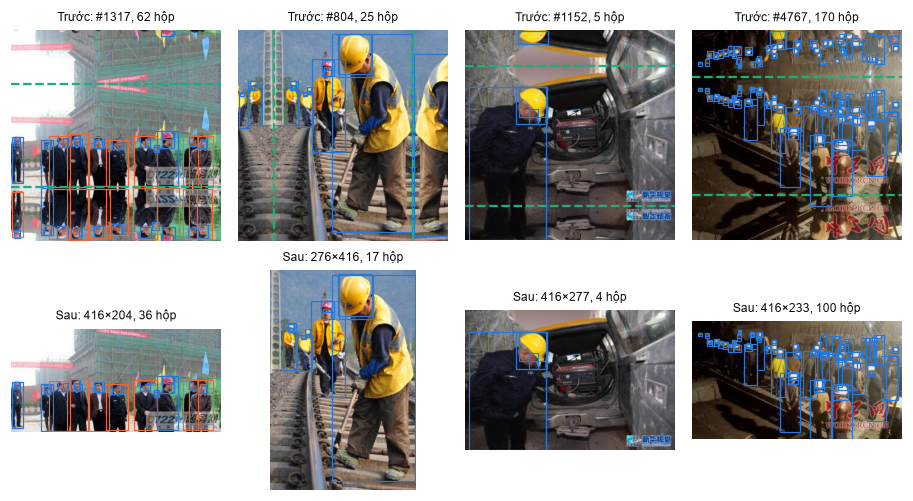

In [5]:
st = stats.set_index("filename")
def draw(ax, img, boxes_xyxy, title, lines=()):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    for c, x1, y1, x2, y2 in boxes_xyxy:
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, linewidth=0.8,
                                   edgecolor=ORANGE if CLASSES[c] == PRIORITY else BLUE))
    for kind, v in lines:
        (ax.axhline if kind == "h" else ax.axvline)(v, color=AQUA, linewidth=1.5, linestyle="--")
    ax.set_title(title, fontsize=8)
    ax.axis("off")

def yolo_boxes(path, w, h):
    out = []
    for line in path.read_text().splitlines():
        c, x, y, bw, bh = map(float, line.split())
        out.append((int(c), (x - bw / 2) * w, (y - bh / 2) * h, (x + bw / 2) * w, (y + bh / 2) * h))
    return out

examples = ["hard_hat_workers1317", "hard_hat_workers804", "hard_hat_workers1152", "hard_hat_workers4767"]
fig, axes = plt.subplots(2, len(examples), figsize=(2.1 * len(examples), 4.6), gridspec_kw={"height_ratios": [1, 1]})
for col, stem in zip(axes.T, examples):
    r = split.set_index("filename").loc[stem]
    orig = cv2.imread(str(ROOT / "data/SHEL5K/Images" / f"{stem}.png"))
    H, W = orig.shape[:2]
    pad = int(r.pad_width)
    lines = [("h", pad), ("h", H - pad)] if r.pad_axis == "tb" else [("v", pad), ("v", W - pad)]
    draw(col[0], orig, yolo_boxes(ROOT / "data/SHEL5K_yolo/labels" / f"{stem}.txt", W, H),
         f"Trước: {stem.replace('hard_hat_workers', '#')}, {int(r.boxes_before)} hộp", lines)
    new = cv2.imread(str(DATA / "images" / r.split / f"{stem}.png"))
    draw(col[1], new, yolo_boxes(DATA / "labels" / r.split / f"{stem}.txt", new.shape[1], new.shape[0]),
         f"Sau: {new.shape[1]}×{new.shape[0]}, {int(r.boxes_after)} hộp")
fig.tight_layout()
save(fig, "fig_before_after_examples.png")

**Diễn giải.** Hàng trên là ảnh gốc với biên dải đệm (nét đứt), hàng dưới là ảnh sau khi cắt. Ảnh #1317 có cả nửa dưới là
dải phản chiếu nên số hộp giảm từ 62 xuống 36; ảnh #804 được cắt hai mép trái – phải; ở ảnh #1152, hộp người kéo dài
sang phần chân phản chiếu được cắt về đúng phần người thật.

## 5. Kết quả chia tập

Số lượng:
       images  boxes  helmet  head  head_with_helmet  person_with_helmet  \
train    3522  46550   10937  3786              9729                9699   
val       751   9955    2329   813              2079                2078   
test      727   9929    2300   812              2079                2080   

       person_no_helmet  face  
train              3487  8912  
val                 750  1906  
test                743  1915  

Tỉ lệ (%):
       helmet  head  head_with_helmet  person_with_helmet  person_no_helmet  \
train    70.3  70.0              70.1                70.0              70.0   
val      15.0  15.0              15.0                15.0              15.1   
test     14.8  15.0              15.0                15.0              14.9   

       face  images  
train  70.0    70.4  
val    15.0    15.0  
test   15.0    14.5  

Độ lệch lớn nhất so với 70/15/15: 0.46 điểm phần trăm


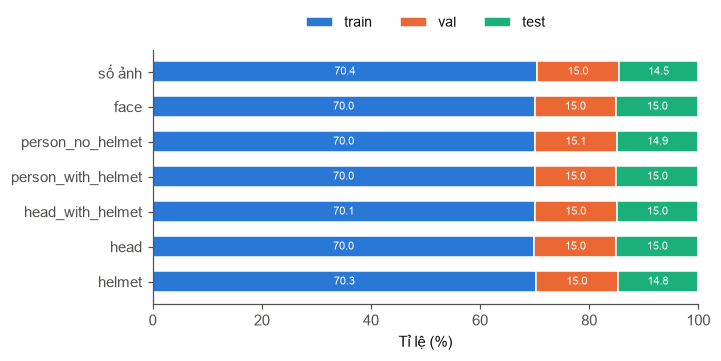


Nhóm độ sáng theo tập (%):
light_group   tối  bình thường  sáng
split                               
train         9.6         80.4  10.1
val          11.5         78.8   9.7
test         10.6         79.5   9.9


Khoảng cách Hamming nhỏ nhất giữa hai ảnh khác tập: 7 (ngưỡng gần trùng: 6)


In [6]:
tab = pd.DataFrame({s: summary["splits"][s] for s in SPLITS}).T
share = tab[CLASSES + ["images"]].div(tab[CLASSES + ["images"]].sum()) * 100
print("Số lượng:"); print(tab[["images", "boxes"] + CLASSES])
print("\nTỉ lệ (%):"); print(share.round(1))
print(f"\nĐộ lệch lớn nhất so với 70/15/15: {(share - np.array([[70], [15], [15]])).abs().max().max():.2f} điểm phần trăm")

fig, ax = plt.subplots(figsize=(6.4, 3.0))
cols = CLASSES + ["images"]
left = np.zeros(len(cols))
for s, color in zip(SPLITS, [BLUE, ORANGE, AQUA]):
    v = share.loc[s, cols].values
    ax.barh(cols, v, left=left, color=color, height=0.6, label=s, edgecolor="white", linewidth=1)
    for i, (l, w) in enumerate(zip(left, v)):
        ax.text(l + w / 2, i, f"{w:.1f}", ha="center", va="center", fontsize=7.5, color="white")
    left += v
ax.set_yticks(range(len(cols)), CLASSES + ["số ảnh"])
ax.set_xlabel("Tỉ lệ (%)")
ax.set_xlim(0, 100)
ax.grid(visible=False)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.18), frameon=False, fontsize=9)
save(fig, "fig_split_balance.png")

light = pd.crosstab(split.merge(stats[["filename", "light_group"]], on="filename").split,
                    split.merge(stats[["filename", "light_group"]], on="filename").light_group, normalize="index") * 100
print("\nNhóm độ sáng theo tập (%):"); print(light.reindex(SPLITS)[["tối", "bình thường", "sáng"]].round(1))

# Kiểm tra rò rỉ: khoảng cách dHash nhỏ nhất giữa hai ảnh thuộc hai tập khác nhau
m = split[["filename", "split"]].merge(stats[["filename", "dhash"]], on="filename")
h = np.array([int(x, 16) for x in m.dhash], dtype=np.uint64)
sp = m.split.to_numpy()
cross_min = 64
for start in range(0, len(h), 500):
    d = np.bitwise_count(h[start:start + 500, None] ^ h[None, :]).astype(int)
    d[sp[start:start + 500, None] == sp[None, :]] = 64
    cross_min = min(cross_min, d.min())
print(f"Khoảng cách Hamming nhỏ nhất giữa hai ảnh khác tập: {cross_min} (ngưỡng gần trùng: 6)")
assert cross_min > 6

**Diễn giải.** Mọi lớp có tỉ lệ 70,0–70,3% / 15,0–15,1% / 14,8–15,0% giữa train / val / test; số ảnh 70,4 / 15,0 / 14,5%
(độ lệch lớn nhất 0,46 điểm phần trăm). Cả 98 nhóm ảnh gần trùng nằm trọn trong một tập, và khoảng cách dHash nhỏ nhất
giữa hai ảnh khác tập là 7, lớn hơn ngưỡng gần trùng 6: không có rò rỉ do ảnh trùng. Nhóm độ sáng cũng phân bố tương
đương giữa các tập (ảnh tối chiếm 9,6–11,5%) dù không được dùng để phân tầng, nên phân tích lỗi theo điều kiện chiếu
sáng ở tuần 8 sẽ có đủ mẫu.

## 6. Trọng số lớp cho M2 (`cls_pw`)

In [7]:
# Cùng công thức với Ultralytics 8.4 (models/yolo/detect/train.py): w = (1 / số hộp) ** cls_pw, chuẩn hóa để trung bình bằng 1
counts = tab.loc["train", CLASSES].astype(float)
weights = pd.DataFrame({"số hộp (train)": counts.astype(int)})
for p in [0.0, 0.5, 1.0]:
    w = (1.0 / counts) ** p
    weights[f"cls_pw = {p}"] = (w / w.mean()).round(3)
print(weights)

                    số hộp (train)  cls_pw = 0.0  cls_pw = 0.5  cls_pw = 1.0
helmet                       10937           1.0         0.779         0.571
head                          3786           1.0         1.324         1.650
head_with_helmet              9729           1.0         0.826         0.642
person_with_helmet            9699           1.0         0.827         0.644
person_no_helmet              3487           1.0         1.380         1.792
face                          8912           1.0         0.863         0.701


**Diễn giải.** Với `cls_pw = 1`, lỗi phân loại của `person_no_helmet` được nhân 1,79 lần và của `head` 1,65 lần, trong
khi `helmet` chỉ 0,57 lần; `cls_pw = 0,5` làm dịu mức chênh (1,38 và 1,32). Trọng số được tính trên tập train sau tiền
xử lý, giống cách Ultralytics tự tính khi huấn luyện; giá trị dùng cho M2 được chọn ở tuần 7.

## 7. Chiến lược tăng cường dữ liệu

Các phép tăng cường dưới đây là mặc định của Ultralytics 8.4 cho bài toán phát hiện đối tượng, được giữ cho cả ba cấu hình
để M0, M1, M2 so sánh được trên cùng điều kiện ("không tăng cường bổ sung" theo đề cương nghĩa là không thêm gì ngoài mặc
định). `erasing` và `auto_augment` trong tệp cấu hình chỉ áp dụng cho bài toán phân loại nên không liệt kê.

| Phép tăng cường | Giá trị | Gắn với dữ liệu |
|---|---|---|
| Mosaic (ghép 4 ảnh) | 1,0; tắt ở 10 epoch cuối | Tăng số đối tượng và ngữ cảnh mỗi ảnh, tạo thêm vật thể nhỏ |
| Lật ngang | 0,5 | Người và mũ đối xứng trái – phải, hợp lý về vật lý |
| Lật dọc | 0 (không dùng) | Người lộn ngược không có ở camera thật; bản sao phản chiếu đã được loại |
| HSV: sắc độ / bão hòa / độ sáng | 0,015 / 0,7 / 0,4 | Độ sáng ảnh trải rộng 10–232 (CV-EDA) |
| Dịch chuyển / tỉ lệ | 0,1 / 0,5 | Đa dạng vị trí và kích thước đối tượng |
| Trọng số lớp `cls_pw` | 0 với M0, M1; M2: chọn trong {0,5; 1,0} ở Tuần 7 | Lớp vi phạm ít nhất (mục 6) |

Để so sánh M1 và M2 quy được nguyên nhân, M2 thay đổi từng yếu tố một; giá trị cụ thể của phần tăng cường có định hướng
được chốt ở Tuần 7 dựa trên kết quả lỗi của M0, M1.

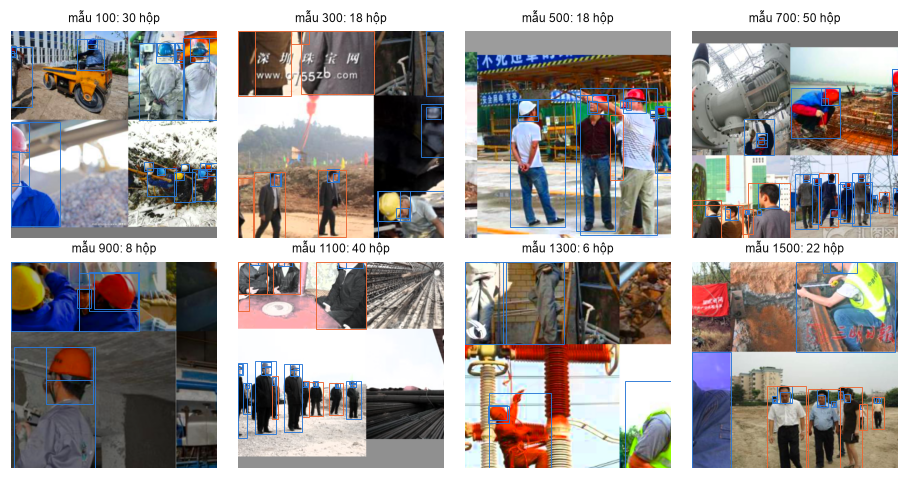

In [8]:
import os, random
os.environ["YOLO_VERBOSE"] = "False"  # tắt log quét dữ liệu của Ultralytics
import torch
from ultralytics.cfg import get_cfg
from ultralytics.data.dataset import YOLODataset

random.seed(0); np.random.seed(0); torch.manual_seed(0)
ds = YOLODataset(img_path=str(DATA / "images/train"), imgsz=640, augment=True, hyp=get_cfg(),
                 data={"names": dict(enumerate(CLASSES)), "nc": len(CLASSES), "channels": 3}, task="detect")
for i in range(64):  # mosaic chọn ảnh ghép từ bộ đệm ảnh vừa nạp; nạp sẵn 64 ảnh như lúc đang huấn luyện
    ds.load_image(i)
fig, axes = plt.subplots(2, 4, figsize=(8.4, 4.4))
for ax, i in zip(axes.ravel(), [100, 300, 500, 700, 900, 1100, 1300, 1500]):
    s = ds[i]
    img = s["img"].permute(1, 2, 0).numpy()  # Ultralytics đã đổi sang RGB; CHW -> HWC
    ax.imshow(img)
    for c, (x, y, w, h) in zip(s["cls"].flatten().int().tolist(), s["bboxes"].tolist()):
        ax.add_patch(plt.Rectangle(((x - w / 2) * 640, (y - h / 2) * 640), w * 640, h * 640, fill=False, linewidth=0.6,
                                   edgecolor=ORANGE if CLASSES[c] == PRIORITY else BLUE))
    ax.set_title(f"mẫu {i}: {len(s['cls'])} hộp", fontsize=8)
    ax.axis("off")
fig.tight_layout()
save(fig, "fig_augmentation_preview.png")

**Diễn giải.** Mỗi ảnh huấn luyện là ghép (mosaic) của 4 ảnh ngẫu nhiên đã qua lật ngang, đổi màu và độ sáng, dịch chuyển,
thay đổi tỉ lệ; các vùng xám là phần đệm letterbox. Không có ảnh lộn ngược. Hình được vẽ sau khi nạp sẵn 64 ảnh vào bộ
đệm của mosaic, giống trạng thái khi đang huấn luyện.

## 8. Tổng kết

| Hạng mục | Kết quả |
|---|---|
| Làm sạch nhãn | Xóa 8 nhãn trùng đã xác nhận; giữ nguyên nhãn thiếu (~1%) và hộp < 4 px theo quyết định đã chốt |
| Cắt dải đệm phản chiếu | 4.965 ảnh; bỏ 9.136 hộp phản chiếu, cắt 2.804 hộp theo biên; số hộp 75.578 → 66.434 |
| Mất cân bằng lớp | 3,67 → 3,13; `person_no_helmet` chiếm 7,5% (trước 6,9%) |
| Chia tập | 3.522 / 751 / 727 ảnh; mọi lớp 70/15/15 (lệch ≤ 0,5 điểm phần trăm); không rò rỉ ảnh gần trùng |
| Tăng cường dữ liệu | Mặc định Ultralytics cho M0, M1, M2; không lật dọc; M2 thêm `cls_pw` (0,5 hoặc 1,0, chọn ở tuần 7) |
| Dữ liệu cho huấn luyện | `data/SHEL5K_processed/` + `data.yaml` (đường dẫn tương đối, dùng được cả local và Colab) |